# Bank customer churn — exploratory analysis

Goal: find which customer attributes go with leaving, to motivate the engineered features.

In [1]:
from churn_prediction.data import load_dataset
from churn_prediction.features import add_features

X, y = load_dataset()
df = add_features(X).assign(churn=y)
y.value_counts(normalize=True)

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

## Churn rate by category

In [2]:
for col in ['Geography', 'Gender', 'NumOfProducts', 'IsActiveMember']:
    print(df.groupby(col)['churn'].agg(['mean', 'size']).round(3))
    print()

            mean  size
Geography             
France     0.162  5014
Germany    0.324  2509
Spain      0.167  2477

         mean  size
Gender             
Female  0.251  4543
Male    0.165  5457

                mean  size
NumOfProducts             
1              0.277  5084
2              0.076  4590
3              0.827   266
4              1.000    60

                 mean  size
IsActiveMember             
0               0.269  4849
1               0.143  5151



## Churn rate by age band

age_band
under30    0.076
30-39      0.109
40-49      0.308
50-59      0.560
60+        0.279
Name: churn, dtype: float64

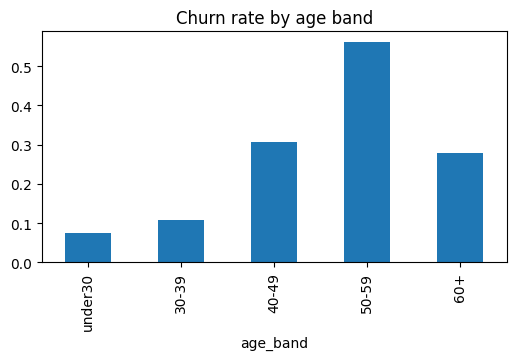

In [3]:
order = ['under30', '30-39', '40-49', '50-59', '60+']
rates = df.groupby('age_band')['churn'].mean().reindex(order)
rates.plot.bar(figsize=(6, 3), title='Churn rate by age band');
rates.round(3)

## Zero balances

In [4]:
print('share with zero balance:', round(df['balance_zero'].mean(), 3))
df.groupby('balance_zero')['churn'].mean().round(3)

share with zero balance: 0.362


balance_zero
0    0.241
1    0.138
Name: churn, dtype: float64

## Hypotheses behind each engineered feature

- `age_band`: churn is strongly non-linear in age (peaks in the 50s).
- `balance_zero`: about a third of customers hold no balance — a distinct behaviour.
- `balance_salary_ratio`: share of income kept at the bank, a proxy for engagement.
- `products_x_active`: product holding only matters if the customer is active.